# Bayesian NBA minutes: a challenger to quantile XGBoost

**Target:** minutes conditional on appearance, regular season only. This notebook uses only the supplied silver columns. It does not estimate DNP probability, invent availability data, or use tonight's realized starter designation.

**Experiment:** a hierarchical, positive Student-t regression with player partial pooling and a scale model. Compare it with last-game minutes, EWMA, and quantile XGBoost trained on the **same historical inputs and rows**. The original XGBoost results are contextual references, since their availability and starting features differ.

This revision addresses an all-NaN prior prediction reported in the user's run. Input finiteness is checked before model construction. The likelihood uses the exact positive Student-t log density, and prior/predictive draws use SciPy's survival-function inverse. This avoids relying on `pm.Truncated` random generation. The precise cause of the original NaNs is not established by the pasted output.

The code has been checked structurally here; fitting and package compatibility still need verification in the user's NBA environment.

## Run order

1. Install dependencies in your NBA environment; set `PROJECT_ROOT` and inspect minutes units.
2. Load/audit data and build history. Inspect finite prior predictions, then run the separate smoke-fit cell.
3. Run NUTS diagnostics before trusting probabilities. ADVI is an optional speed experiment, not a convergence certificate.
4. Run the training-period walk-forward comparison. Inspect paired losses, calibration, slices, and runtime.
5. Freeze decisions before enabling the previously scored 2025–26 holdout. Further changes informed by it require a new prospective evaluation period.
6. Export posterior parameters and preprocessing; use the sampler to replace only the minutes component in your existing independent-uniform rate simulator. Keep its conditional stat PMF unchanged.


## Model and tradeoffs

For player i, $M_i\mid M_i>0$ follows a Student-t distribution truncated below zero:

$$
\mu_i=\mathrm{EWMA}_i/10+a+x_i^\top\beta+u_{player(i)},\qquad
\sigma_i=\exp(s_0+z_i^\top\gamma),\qquad u_j\sim N(0,\tau^2).
$$

The likelihood uses `minutes / 10`; predictions are converted back to minutes. `nu = 2 + Exponential(1/10)` permits heavy tails with finite component variance. There is no hard 48-minute ceiling because overtime is possible. Check the amount of mass above 48 and 60; an implausible upper tail is evidence against this likelihood, not something to hide by clipping.

Partial pooling may help sparse histories; it is not guaranteed to outperform trees. The location regression has limited curvature from an EWMA-squared term and a historical starter-rate interaction. Scale depends on expected minutes, prior variability, and prior starter rate. These are initial choices, not features selected using the holdout.

Positive truncation means `mu` is a location parameter, **not the predictive mean or median**. All forecasts and intervals below come from the posterior predictive distribution, including outcome noise and parameter uncertainty. A new player's effect is drawn from the population prior conditional on each posterior `tau` draw.

The likelihood is implemented with `pm.Potential` as `log StudentT density - log P(StudentT > 0)`. The normalizer depends on location, scale, and degrees of freedom and is included in fitting. A potential does not produce an observed predictive variable; use the explicit predictive functions below for draws, CDFs, and log scores.

This is a marginal player model: draws do not enforce a team rotation total, and independent player draws are not suitable for joint team markets without additional work.


In [37]:
# Optional environment install, in a separate cell before these imports:
# %pip install "pymc>=5.10,<7" "xgboost>=2,<4" pandas numpy scipy arviz matplotlib pyarrow
from pathlib import Path
import inspect
import json
import os
import platform
import time
import importlib.metadata

import numpy as np
import pandas as pd
import scipy.stats as st
from scipy.special import logsumexp
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from IPython.display import display
from xgboost import XGBRegressor


def repo_root():
    explicit = os.environ.get("NBA_PROJECT_ROOT")
    if explicit:
        candidate = Path(explicit).expanduser().resolve()
        if not (candidate / "data/silver/nba").is_dir():
            raise FileNotFoundError(f"NBA_PROJECT_ROOT has no data/silver/nba: {candidate}")
        return candidate
    starts = []
    notebook_path = globals().get("__vsc_ipynb_file__")
    if notebook_path:
        starts.append(Path(notebook_path).resolve().parent)
    starts.append(Path.cwd().resolve())
    for start in starts:
        for candidate in (start, *start.parents):
            if (candidate / "data/silver/nba").is_dir():
                return candidate
    raise RuntimeError("Set NBA_PROJECT_ROOT or start the kernel inside the NBA project")

ROOT = repo_root()
PROJECT_ROOT = ROOT
OUTPUT_DIR = ROOT / "models/bayesian_minutes_experiment"
SEASONS = ["2019-20", "2020-21", "2021-22", "2022-23", "2023-24", "2024-25", "2025-26"]
OPTIONAL_SEASONS = ["2026-27"]  # Loaded if present; excluded from fixed train/holdout ranges.
MIN_SEC_UNIT = "seconds"  # Verify against min and minutes in the label audit.
TRAIN_START = pd.Timestamp("2019-10-22")
TRAIN_END = pd.Timestamp("2025-04-14")
HOLDOUT_START = pd.Timestamp("2025-10-21")
HOLDOUT_END = pd.Timestamp("2026-04-13")
FOLD_EDGES = pd.to_datetime([
    "2022-11-02", "2023-02-07", "2023-12-05",
    "2024-03-17", "2025-01-02", "2025-04-12",
])
QUANTILES = np.array([.05, .10, .20, .30, .40, .50, .60, .70, .80, .90, .95])
SEED = 20260412
METHOD = "nuts"
DRAWS, TUNE, CHAINS = 1000, 1000, 4
PREDICTIVE_DRAWS = 1024
ADVI_STEPS = 40000
ADVI_VALIDATED = False  # Set only after agreement with converged NUTS.
RUN_SMOKE = True
RUN_WALK_FORWARD = True
RUN_MATCHED_XGB = True
XGB_PARAMS = {"max_depth": 4, "n_estimators": 1198, "tree_method": "hist", "n_jobs": 4}
RUN_FINAL_TRAIN_FIT = True
RUN_HOLDOUT = True
CONFIG_FROZEN = False

versions = {name: importlib.metadata.version(name) for name in
            ["pymc", "xgboost", "pandas", "numpy", "scipy", "arviz"]}
display({"python": platform.python_version(), "packages": versions, "project_root": str(ROOT)})


{'python': '3.12.10',
 'packages': {'pymc': '6.3.2',
  'xgboost': '3.4.1',
  'pandas': '3.0.5',
  'numpy': '2.5.3',
  'scipy': '1.18.1',
  'arviz': '1.3.0'},
 'project_root': '/Users/alexgonzalez/Documents/nba_quant'}

## 1. Read only permitted columns; verify the label

`min_sec` is interpreted as elapsed seconds by default; inspect its raw values next to `min` before continuing. Clock strings such as `32:15` are parsed as minutes:seconds. Numeric `min` and `minutes` are minutes. A zero in the preferred source remains a DNP even if another column disagrees. Malformed/nonfinite values fall back to the next source.

The seven original files must exist. `2026-27` is optional: it is loaded only if present and does not enter the fixed training or holdout intervals. Every loaded file is projected to the permitted columns, rather than loading all 189 columns.

The label audit records which source supplied each label and identifies disagreements. Your pasted holdout count was 26,649 versus the original reference's 26,648; reconcile that one-row difference before claiming a reproduction. The audit is evidence to investigate, not an assertion of its cause.

The seven required files must exist. Duplicate player-game keys, invalid dates, and minutes outside 0–80 stop execution. The 80-minute limit is a data audit, not a predictive cap. Review any rejected rows rather than silently changing their labels.


In [24]:
READ_COLUMNS = ["player_id", "game_id", "game_date", "season_year", "team_id",
                "start_position", "min_sec", "min", "minutes",
                "game_total", "player_team_spread"]


def parse_time(values, numeric_unit="minutes"):
    text = values.astype("string").str.strip()
    numeric = pd.to_numeric(text, errors="coerce")
    if numeric_unit == "seconds":
        numeric = numeric / 60
    clock = text.str.extract(r"^(\d+):(\d{1,2}(?:\.\d+)?)$")
    seconds = pd.to_numeric(clock[1], errors="coerce")
    clock_minutes = pd.to_numeric(clock[0], errors="coerce") + seconds / 60
    numeric = numeric.where(clock[0].isna(), clock_minutes.where(seconds < 60))
    numeric = numeric.to_numpy(dtype=float, na_value=np.nan)
    numeric[~np.isfinite(numeric)] = np.nan
    return pd.Series(numeric, index=values.index, dtype=float)


def load_silver(root):
    if MIN_SEC_UNIT not in {"seconds", "minutes"}:
        raise ValueError("MIN_SEC_UNIT must be seconds or minutes")
    required = [root / f"data/silver/nba/{s}/regular_season/player_gamelogs.parquet" for s in SEASONS]
    missing = [str(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError("Missing required silver files: " + ", ".join(missing))
    optional = [root / f"data/silver/nba/{s}/regular_season/player_gamelogs.parquet" for s in OPTIONAL_SEASONS]
    paths = required + [p for p in optional if p.is_file()]
    raw = pd.concat([pd.read_parquet(p, columns=READ_COLUMNS) for p in paths], ignore_index=True)
    print("Loaded seasons:", [p.parents[1].name for p in paths])
    display(raw[["min_sec", "min", "minutes"]].sample(min(12, len(raw)), random_state=SEED))
    sources = pd.DataFrame({"from_min_sec": parse_time(raw.min_sec, MIN_SEC_UNIT),
                            "from_min": parse_time(raw["min"]),
                            "from_minutes": parse_time(raw.minutes)})
    label = sources.from_min_sec.fillna(sources.from_min).fillna(sources.from_minutes)
    source_name = pd.Series("missing", index=raw.index, dtype="string")
    for source in ["from_minutes", "from_min", "from_min_sec"]:
        source_name.loc[sources[source].notna()] = source
    spread = sources.max(axis=1) - sources.min(axis=1)
    audit = raw[["player_id", "game_id", "game_date", "season_year"]].copy()
    audit = pd.concat([audit, sources], axis=1)
    audit["label"] = label
    audit["label_source"] = source_name
    audit["source_disagreement_gt_0_1"] = spread > .1
    audit["appearance_disagreement"] = ((sources > 0).any(axis=1)
                                        & ((sources == 0).any(axis=1)))
    display(audit.label_source.value_counts())
    print("Source disagreements >0.1 minute:", int(audit.source_disagreement_gt_0_1.sum()))
    display(audit.loc[audit.source_disagreement_gt_0_1 | audit.appearance_disagreement].head(20))
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    audit.to_csv(OUTPUT_DIR / "label_audit.csv", index=False)
    raw["minutes"] = label
    raw["game_date"] = pd.to_datetime(raw.game_date, errors="raise").dt.normalize()
    if raw[["player_id", "game_id", "season_year", "game_date"]].isna().any().any():
        raise ValueError("Missing history keys")
    if raw.duplicated(["player_id", "game_id"]).any():
        raise ValueError("Duplicate player-game keys")
    invalid = ~np.isfinite(label) | (label < 0) | (label > 80)
    if invalid.any():
        display(audit.loc[invalid].head(20))
        raise ValueError(f"Review {invalid.sum()} invalid minutes labels; see label_audit.csv")
    display(raw.groupby("season_year").agg(rows=("minutes", "size"),
        appearances=("minutes", lambda x: int((x > 0).sum())), max_minutes=("minutes", "max")))
    return raw

raw = load_silver(ROOT)


Loaded seasons: ['2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25', '2025-26', '2026-27']


,min_sec,min,minutes
8660,26:47,26.783333,26.783333
22355,44:20,44.335000,44.335000
160601,33:22,33.366667,33.366667
58476,30:28,30.463333,30.463333
158921,14:16,14.270000,14.270000
148723,13:54,13.896667,13.896667
147456,38:53,38.883333,38.883333
159763,32:52,32.866667,32.866667
54461,3:55,3.916667,3.916667
149945,14:05,14.078333,14.078333


label_source
from_min_sec    176628
from_min           432
Name: count, dtype: int64[pyarrow]

Source disagreements >0.1 minute: 0


,player_id,game_id,game_date,season_year,from_min_sec,from_min,from_minutes,label,label_source,source_disagreement_gt_0_1,appearance_disagreement
839,1629626,0021901281,2020-08-08T00:00:00,2019-20,0.0,0.005000,0.005000,0.0,from_min_sec,False,True
840,1629730,0021901281,2020-08-08T00:00:00,2019-20,0.0,0.005000,0.005000,0.0,from_min_sec,False,True
6119,1628394,0021900770,2020-02-07T00:00:00,2019-20,0.0,0.003333,0.003333,0.0,from_min_sec,False,True
6120,1626246,0021900770,2020-02-07T00:00:00,2019-20,0.0,0.003333,0.003333,0.0,from_min_sec,False,True
14039,1626246,0021900398,2019-12-16T00:00:00,2019-20,0.0,0.005000,0.005000,0.0,from_min_sec,False,True
35783,1629605,0022000485,2021-02-23T00:00:00,2020-21,0.0,0.001667,0.001667,0.0,from_min_sec,False,True
48495,1629674,0022101086,2022-03-23T00:00:00,2021-22,0.0,0.003333,0.003333,0.0,from_min_sec,False,True
102865,1630543,0022300948,2024-03-13T00:00:00,2023-24,0.0,0.005000,0.005000,0.0,from_min_sec,False,True
114417,203469,0022300410,2023-12-26T00:00:00,2023-24,0.0,0.006667,0.006667,0.0,from_min_sec,False,True
119290,203552,0022300238,2023-11-22T00:00:00,2023-24,0.0,0.006667,0.006667,0.0,from_min_sec,False,True


,rows,appearances,max_minutes
season_year,,,
2019-20,22393,22387,51.550000
2020-21,23054,23053,50.500000
2021-22,26039,26035,56.516667
2022-23,25894,25892,55.100000
2023-24,26401,26393,53.950000
2024-25,26306,26302,53.166667
2025-26,26651,26648,52.300000
2026-27,322,322,41.150000


## 2. Build history without tonight's outcomes

Only positive-minute appearances enter player histories. All windows reset by player-season, and all box-score/starting inputs are shifted. The 10-game windows here mean **10 player appearances**, not 10 team games; they intentionally have different names from your original features.

Market terms are included using the supplied pregame columns. Verify their historical timestamp before interpreting this as an hour-before-tip backtest. If that timestamp cannot be established, run the same comparison with market terms removed from both models.

For live use, append a row with keys and pregame inputs, leave `minutes` and `start_position` missing, and set `_target=True`. Do not use the appended row as an observed appearance. Your caller must supply tonight's actual player/team keys; this notebook does not infer a current roster from past participation.


In [25]:
def build_features(frame):
    d = frame.copy()
    if "_target" not in d:
        d["_target"] = False
    d["game_date"] = pd.to_datetime(d["game_date"]).dt.normalize()
    d = d.loc[(d["minutes"] > 0) | d["_target"]].copy()
    d = d.sort_values(["player_id", "season_year", "game_date", "game_id"]).reset_index(drop=True)
    if d.duplicated(["player_id", "season_year", "game_date"]).any():
        raise ValueError("Ambiguous multiple rows for one player-date; review schedule/order")
    groups = ["player_id", "season_year"]
    d["_observed_minutes"] = d["minutes"].where(~d["_target"])
    d["_observed_start"] = d["start_position"].astype("string").str.strip().isin(["G", "F", "C"]).astype(float).where(~d["_target"])
    for _, g in d.groupby(groups, sort=False):
        if g["_target"].any() and (g["_target"].sum() != 1 or not g["_target"].iloc[-1]):
            raise ValueError("Each player-season may have one live target, after all history")
    gm = d.groupby(groups, sort=False)["_observed_minutes"]
    gs = d.groupby(groups, sort=False)["_observed_start"]
    d["b_min_lag_1"] = gm.transform(lambda s: s.shift(1))
    d["b_min_ewm_10"] = gm.transform(lambda s: s.shift(1).ewm(halflife=10, adjust=False).mean())
    d["b_min_mean_10"] = gm.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
    d["b_min_p80_10"] = gm.transform(lambda s: s.shift(1).rolling(10, min_periods=3).quantile(.8))
    p20 = gm.transform(lambda s: s.shift(1).rolling(10, min_periods=3).quantile(.2))
    d["b_min_width_10"] = d["b_min_p80_10"] - p20
    d["b_start_rate_10"] = gs.transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
    d["b_season_start_rate"] = gs.transform(lambda s: s.shift(1).expanding(min_periods=1).mean())
    d["b_prior_appearances"] = d.groupby(groups, sort=False).cumcount()
    previous_date = d.groupby(groups, sort=False)["game_date"].shift(1)
    d["b_days_since"] = (d["game_date"] - previous_date).dt.days.clip(upper=30)
    d["b_appearances_7d"] = 0
    for _, g in d.groupby(groups, sort=False):
        dates = g["game_date"].to_numpy(dtype="datetime64[D]")
        left = np.searchsorted(dates, dates - np.timedelta64(7, "D"), side="left")
        d.loc[g.index, "b_appearances_7d"] = np.arange(len(g)) - left
    d["b_abs_spread"] = pd.to_numeric(d["player_team_spread"], errors="coerce").abs()
    d["b_implied_total"] = (pd.to_numeric(d["game_total"], errors="coerce")
                            - pd.to_numeric(d["player_team_spread"], errors="coerce")) / 2
    d["b_ewm_squared"] = d["b_min_ewm_10"] ** 2
    d["b_start_x_ewm"] = d["b_start_rate_10"] * d["b_min_ewm_10"]
    return d.drop(columns=["_observed_minutes", "_observed_start"])

LOCATION_FEATURES = ["b_min_lag_1", "b_min_ewm_10", "b_min_mean_10",
    "b_min_p80_10", "b_min_width_10", "b_start_rate_10", "b_season_start_rate",
    "b_prior_appearances", "b_days_since", "b_appearances_7d", "b_abs_spread",
    "b_implied_total", "b_ewm_squared", "b_start_x_ewm"]
SCALE_FEATURES = ["b_min_ewm_10", "b_min_width_10", "b_start_rate_10"]

def check_history_invariance():
    dates = pd.to_datetime(["2024-10-20", "2024-10-22", "2024-10-25", "2025-10-20"])
    fixture = pd.DataFrame({"player_id": [1] * 4, "game_id": [10, 11, 12, 13],
        "game_date": dates, "season_year": [2024, 2024, 2024, 2025], "team_id": [7] * 4,
        "minutes": [20., 30., 25., 18.], "start_position": ["G", "", "F", ""],
        "game_total": [220.] * 4, "player_team_spread": [-4.] * 4})
    built = build_features(fixture)
    changed = fixture.copy()
    changed.loc[2, ["minutes", "start_position"]] = [60., ""]
    rebuilt = build_features(changed)
    pd.testing.assert_series_equal(built.loc[2, LOCATION_FEATURES], rebuilt.loc[2, LOCATION_FEATURES])
    assert built.loc[2, "b_min_lag_1"] == 30
    assert built.loc[2, "b_appearances_7d"] == 2
    assert pd.isna(built.loc[3, "b_min_lag_1"])
    assert built.loc[3, "b_prior_appearances"] == 0
    live = fixture.iloc[:3].copy()
    live["_target"] = [False, False, True]
    live.loc[2, ["minutes", "start_position"]] = [np.nan, None]
    live_features = build_features(live)
    pd.testing.assert_series_equal(built.loc[2, LOCATION_FEATURES], live_features.loc[2, LOCATION_FEATURES])
    dnp = fixture.iloc[:3].copy()
    dnp.loc[1, "minutes"] = 0
    dnp_built = build_features(dnp)
    assert dnp_built.loc[dnp_built.game_id == 12, "b_min_lag_1"].iloc[0] == 20
    print("History invariance, season reset, DNP exclusion, and live-row checks passed.")

check_history_invariance()

features = build_features(raw)
train_pool = features.loc[features.game_date.between(TRAIN_START, TRAIN_END, inclusive="left")].copy()
holdout = features.loc[features.game_date.between(HOLDOUT_START, HOLDOUT_END, inclusive="left")].copy()
display(train_pool[LOCATION_FEATURES].isna().mean().rename("missing_fraction"))
print("Training appearances:", len(train_pool), "Holdout appearances:", len(holdout))


History invariance, season reset, DNP exclusion, and live-row checks passed.


b_min_lag_1            0.022351
b_min_ewm_10           0.022351
b_min_mean_10          0.022351
b_min_p80_10           0.065979
b_min_width_10         0.065979
b_start_rate_10        0.022351
b_season_start_rate    0.022351
b_prior_appearances    0.000000
b_days_since           0.022351
b_appearances_7d       0.000000
b_abs_spread           0.023923
b_implied_total        0.027162
b_ewm_squared          0.022351
b_start_x_ewm          0.022351
Name: missing_fraction, dtype: float64

Training appearances: 150062 Holdout appearances: 26648


## 3. Training-only preprocessing

Medians, scales, and player vocabulary are fitted inside each fold. Missing-history indicators distinguish a rookie/season opener from an ordinary imputed value. Player identity is used only for Bayesian partial pooling. The matched tree baseline uses the same numeric covariates; player identity is an intentional additional Bayesian modeling choice.

Only the original objective, depth, and tree count were supplied. Copy the remaining XGBoost settings into `XGB_PARAMS` and verify the knots before interpreting this as a faithful retraining of your original model.


In [26]:
def fit_preprocessor(train):
    values = train[LOCATION_FEATURES].astype(float).replace([np.inf, -np.inf], np.nan)
    med = values.median().fillna(0.)
    filled = values.fillna(med)
    center = filled.mean()
    scale = filled.std(ddof=0).replace(0, 1).fillna(1)
    players = sorted(train.player_id.astype(str).unique())
    return {"median": med.to_dict(), "center": center.to_dict(), "scale": scale.to_dict(),
            "players": players, "features": list(LOCATION_FEATURES), "scale_features": list(SCALE_FEATURES)}

def transform(frame, prep):
    names = prep["features"]
    v = frame[names].astype(float).replace([np.inf, -np.inf], np.nan)
    missing = v.isna().to_numpy(dtype=float)
    filled = v.fillna(pd.Series(prep["median"]))
    standardized = (filled - pd.Series(prep["center"])) / pd.Series(prep["scale"])
    x = np.column_stack([standardized.to_numpy(dtype=float), missing])
    z = standardized[prep["scale_features"]].to_numpy(dtype=float)
    lookup = {p: i for i, p in enumerate(prep["players"])}
    player = frame.player_id.astype(str).map(lookup).fillna(-1).to_numpy(dtype=int)
    baseline = filled["b_min_ewm_10"].to_numpy(dtype=float) / 10
    for name, array in {"x": x, "z": z, "baseline": baseline}.items():
        if not np.isfinite(array).all():
            raise ValueError(f"Nonfinite {name}; inspect input features and preprocessing")
    return {"x": x, "z": z, "player": player, "baseline": baseline,
            "ids": frame.player_id.astype(str).to_numpy()}


def make_model(train, prep, include_likelihood=True):
    inputs = transform(train, prep)
    y = train.minutes.to_numpy(dtype=float) / 10
    if not np.isfinite(y).all() or (y <= 0).any():
        raise ValueError("The training label must be finite positive minutes")
    if (inputs["player"] < 0).any():
        raise ValueError("Training player missing from the training vocabulary")
    coords = {"feature": prep["features"] + [f"missing_{f}" for f in prep["features"]],
              "scale_feature": prep["scale_features"], "player": prep["players"]}
    with pm.Model(coords=coords) as model:
        intercept = pm.Normal("intercept", 0, .5)
        beta = pm.Normal("beta", 0, .3, dims="feature")
        tau = pm.HalfNormal("tau", .5)
        player_raw = pm.Normal("player_raw", 0, 1, dims="player")
        player_effect = pm.Deterministic("player_effect", tau * player_raw, dims="player")
        scale_intercept = pm.Normal("scale_intercept", np.log(.5), .4)
        gamma = pm.Normal("gamma", 0, .2, dims="scale_feature")
        nu = pm.Deterministic("nu", 2 + pm.Exponential("nu_minus_two", .1))
        mu = inputs["baseline"] + intercept + pm.math.dot(inputs["x"], beta) + player_effect[inputs["player"]]
        sigma = pm.math.exp(scale_intercept + pm.math.dot(inputs["z"], gamma))
        if include_likelihood:
            base = pm.StudentT.dist(nu=nu, mu=mu, sigma=sigma)
            standardized_t = pm.StudentT.dist(nu=nu, mu=0, sigma=1)
            log_survival_at_zero = pm.logcdf(standardized_t, mu / sigma)
            pm.Potential("minutes_loglik", (pm.logp(base, y) - log_survival_at_zero).sum())
    return model


def fit_bayes(train, method=METHOD, draws=DRAWS, tune=TUNE, chains=CHAINS):
    prep = fit_preprocessor(train)
    model = make_model(train, prep)
    start = time.perf_counter()
    initial = model.initial_point()
    initial_logp = model.compile_logp()(initial)
    initial_gradient = model.compile_dlogp()(initial)
    if not np.isfinite(initial_logp) or not np.isfinite(initial_gradient).all():
        raise FloatingPointError("Nonfinite initial log density/gradient; resolve before NUTS")
    with model:
        if method == "nuts":
            idata = pm.sample(draws=draws, tune=tune, chains=chains, cores=min(chains, 2),
                target_accept=.95, random_seed=SEED, idata_kwargs={"log_likelihood": False})
            approximation_loss = None
        elif method == "advi":
            approx = pm.fit(n=ADVI_STEPS, method="advi", random_seed=SEED)
            idata = approx.sample(draws=draws, random_seed=SEED, return_inferencedata=True)
            approximation_loss = np.asarray(approx.hist)
        else:
            raise ValueError("method must be nuts or advi")
    return {"idata": idata, "prep": prep, "method": method,
            "fit_seconds": time.perf_counter() - start, "advi_loss": approximation_loss,
            "train_rows": len(train), "train_start": str(train.game_date.min()),
            "train_end": str(train.game_date.max())}


def parameter_arrays(group):
    result = {}
    for name in ["intercept", "beta", "tau", "player_effect", "scale_intercept", "gamma", "nu"]:
        v = group[name].stack(sample=("chain", "draw"))
        other = [d for d in v.dims if d != "sample"]
        result[name] = v.transpose("sample", *other).values
    return result


def posterior_arrays(fit):
    return parameter_arrays(fit["idata"].posterior)

def chain_bfmi(idata):
    # ArviZ 1 returns BFMI as a DataTree. np.asarray on that object raises.
    values = az.bfmi(idata)
    energy = getattr(values, "energy", values)
    return np.ravel(np.asarray(getattr(energy, "values", energy), dtype=float))


## 5. Posterior predictive draws, CDF, and density

Sample from the **positive truncated** distribution, not a clipped untruncated draw. Rows are processed in batches to avoid a draws × full-season memory allocation. Conditional CDFs are averaged across posterior draws; predictive log density uses log-sum-exp and the truncation normalizer.

For your existing simulator, `inverse_minutes_cdf(fit, rows, uniforms)` maps one minutes uniform per simulation to the posterior-mixture inverse CDF. Draw the rate uniform independently and keep the existing conditional stat PMF. Direct posterior predictive samples below are another way to obtain the same marginal minutes distribution.


In [27]:
def component_parameters(fit, frame, n_draws=PREDICTIVE_DRAWS, seed=SEED):
    rng = np.random.default_rng(seed)
    posterior = fit.get("posterior")
    p = posterior if posterior is not None else posterior_arrays(fit)
    chosen = rng.choice(len(p["intercept"]), size=n_draws, replace=n_draws > len(p["intercept"]))
    a = {k: v[chosen] for k, v in p.items()}
    inputs = transform(frame, fit["prep"])
    effects = np.zeros((n_draws, len(frame)))
    known = inputs["player"] >= 0
    effects[:, known] = a["player_effect"][:, inputs["player"][known]]
    if (~known).any():
        unseen, inverse = np.unique(inputs["ids"][~known], return_inverse=True)
        new_effects = rng.normal(size=(n_draws, len(unseen))) * a["tau"][:, None]
        effects[:, ~known] = new_effects[:, inverse]
    mu = inputs["baseline"][None, :] + a["intercept"][:, None] + a["beta"] @ inputs["x"].T + effects
    sigma = np.exp(a["scale_intercept"][:, None] + a["gamma"] @ inputs["z"].T)
    nu = a["nu"][:, None]
    if not all(np.isfinite(v).all() for v in [mu, sigma, nu]) or (sigma <= 0).any() or (nu <= 2).any():
        raise FloatingPointError("Nonfinite or invalid distribution parameters")
    return mu, sigma, nu


def truncated_draws(mu, sigma, nu, seed=SEED):
    rng = np.random.default_rng(seed)
    survival_at_zero = st.t.sf(-mu / sigma, df=nu)
    if not np.isfinite(survival_at_zero).all() or (survival_at_zero <= 0).any():
        raise FloatingPointError("Invalid positive-truncation probability")
    u = rng.uniform(np.finfo(float).eps, 1 - np.finfo(float).eps, size=mu.shape)
    draws = mu + sigma * st.t.isf((1 - u) * survival_at_zero, df=nu)
    if not np.isfinite(draws).all() or (draws < -1e-8).any():
        raise FloatingPointError("Unstable truncated predictions; inspect posterior scale/tails")
    return np.maximum(draws, 0) * 10


def mixture_cdf(minutes, mu, sigma, nu):
    y = np.asarray(minutes) / 10
    ratio = st.t.sf((y - mu) / sigma, df=nu) / st.t.sf(-mu / sigma, df=nu)
    if not np.isfinite(ratio).all():
        raise FloatingPointError("Nonfinite posterior predictive CDF")
    cdf = np.mean(np.clip(1 - ratio, 0, 1), axis=0)
    return np.where(np.asarray(minutes) <= 0, 0, cdf)


def inverse_minutes_cdf(fit, frame, uniforms, n_draws=PREDICTIVE_DRAWS, seed=SEED):
    u = np.asarray(uniforms, dtype=float)
    if u.ndim != 2 or u.shape[1] != len(frame) or not ((u > 0) & (u < 1)).all():
        raise ValueError("uniforms must be simulations × rows and strictly between zero and one")
    mu, sigma, nu = component_parameters(fit, frame, n_draws, seed)
    output = np.empty_like(u)
    for i, target in enumerate(u):
        lo = np.zeros(len(frame))
        hi = np.full(len(frame), 60.)
        for _ in range(40):
            needs_more = mixture_cdf(hi, mu, sigma, nu) < target
            if not needs_more.any():
                break
            hi[needs_more] *= 2
        else:
            raise FloatingPointError("Could not bracket inverse CDF; inspect tails")
        for _ in range(45):
            midpoint = (lo + hi) / 2
            below = mixture_cdf(midpoint, mu, sigma, nu) < target
            lo = np.where(below, midpoint, lo)
            hi = np.where(below, hi, midpoint)
        output[i] = (lo + hi) / 2
    return output


def predict_bayes(fit, frame, batch_size=256, n_draws=PREDICTIVE_DRAWS):
    chunks = []
    start = time.perf_counter()
    for offset in range(0, len(frame), batch_size):
        batch = frame.iloc[offset:offset + batch_size]
        mu, sigma, nu = component_parameters(fit, batch, n_draws, SEED + offset)
        draws = truncated_draws(mu, sigma, nu, SEED + offset + 1)
        q = np.quantile(draws, QUANTILES, axis=0).T
        output = batch[["player_id", "game_id", "game_date", "season_year", "minutes",
                        "start_position", "b_prior_appearances", "b_min_lag_1", "b_min_ewm_10"]].copy()
        for j, knot in enumerate(QUANTILES):
            output[f"q{round(knot * 100):02d}"] = q[:, j]
        y = batch.minutes.to_numpy()[None, :] / 10
        logdensity = (st.t.logpdf((y - mu) / sigma, df=nu) - np.log(sigma)
                      - st.t.logsf(-mu / sigma, df=nu) - np.log(10))
        if not np.isfinite(logdensity).all():
            raise FloatingPointError("Nonfinite predictive log density")
        output["nll"] = -(logsumexp(logdensity, axis=0) - np.log(n_draws))
        output["pit"] = mixture_cdf(batch.minutes.to_numpy(), mu, sigma, nu)
        output["p_gt_48"] = 1 - mixture_cdf(48., mu, sigma, nu)
        output["p_gt_60"] = 1 - mixture_cdf(60., mu, sigma, nu)
        chunks.append(output)
    result = pd.concat(chunks, ignore_index=True)
    result.attrs["predict_seconds"] = time.perf_counter() - start
    return result


## Numerical sampler checks

These checks verify positive support, distribution normalization, and approximate CDF agreement for synthetic Student-t components with both positive and negative locations. They run before the real-data prior check. They test the predictive implementation; they do not establish model calibration or NUTS convergence.


In [28]:
from scipy.integrate import quad


def check_predictive_math():
    cases = [(-.8, .3, 4.), (2., .5, 8.), (4., .8, 12.)]
    for location, scale, degrees in cases:
        mu = np.full((20000, 1), location)
        sigma = np.full_like(mu, scale)
        nu = np.full_like(mu, degrees)
        draws = truncated_draws(mu, sigma, nu, seed=SEED).ravel()
        assert np.isfinite(draws).all() and (draws >= 0).all()
        threshold = max(2., location * 10)
        theoretical = float(mixture_cdf(threshold, mu, sigma, nu)[0])
        empirical = float(np.mean(draws <= threshold))
        assert abs(theoretical - empirical) < .02, (theoretical, empirical)
        log_normalizer = st.t.logsf(-location / scale, df=degrees)
        def density(minutes):
            return np.exp(st.t.logpdf((minutes / 10 - location) / scale, df=degrees)
                          - np.log(scale) - log_normalizer - np.log(10))
        integral, error = quad(density, 0, np.inf, epsabs=1e-9)
        assert abs(integral - 1) < 1e-7, (integral, error)
    print("Synthetic positive-support, normalization, and CDF checks passed.")

check_predictive_math()


Synthetic positive-support, normalization, and CDF checks passed.


## 4. Prior predictions and sampler diagnostics

The pasted run printed all-NaN prior quantiles. Its `P(minutes > 60) = 0.0` is not a valid tail estimate: comparisons with NaN evaluate false. This revision refuses nonfinite inputs, parameters, CDFs, densities, or draws, and uses explicit SciPy prior predictions. A failure message identifies which stage needs investigation.

The prior check and smoke fit are separate cells. Use a representative random training subset rather than `train_pool.tail(...)`: the feature frame is sorted by player-season, so its tail is not a chronological or representative sample.

Before fitting, inspect whether priors produce plausible distributions at low, medium, and high historical minutes. Change overly broad priors using training data only. Priors on several correlated histories can combine to produce excessive tails.

For a serious NUTS fit, examine divergences (target zero), R-hat (rough guide: below 1.01), bulk/tail effective sample sizes (rough guide: above 400), traces, and energy/BFMI. These thresholds are diagnostic prompts, not proof that the model is correct. Full evaluation/export is gated on them; inspect failures before changing thresholds. A short smoke fit will usually fail them.

ADVI can underestimate posterior uncertainty. Inspect its loss trajectory and repeat with another seed; agreement with converged NUTS on a representative training subset is necessary before using it for probability evaluation.


Sampling: [beta, gamma, intercept, nu_minus_two, player_raw, scale_intercept, tau]


Prior minutes q05/q50/q95: [ 1.85494017 22.26043257 51.39276493]
Prior P(minutes > 60): 0.0206


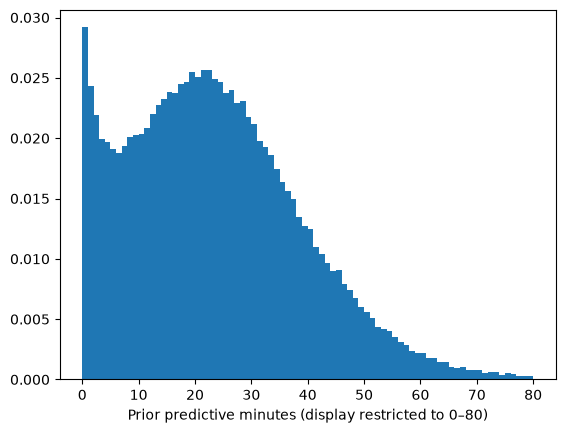

In [29]:
def draw_prior_parameters(model, draws=300):
    parameters = inspect.signature(pm.sample_prior_predictive).parameters
    count_keyword = "draws" if "draws" in parameters else "samples"
    with model:
        return pm.sample_prior_predictive(**{count_keyword: draws}, random_seed=SEED)

prior_train = train_pool.sample(min(500, len(train_pool)), random_state=SEED).copy()
prior_prep = fit_preprocessor(prior_train)
prior_parameters = draw_prior_parameters(make_model(prior_train, prior_prep, include_likelihood=False))
prior_fit = {"posterior": parameter_arrays(prior_parameters.prior), "prep": prior_prep}
prior_mu, prior_sigma, prior_nu = component_parameters(prior_fit, prior_train, n_draws=300)
prior_values = truncated_draws(prior_mu, prior_sigma, prior_nu)
if not np.isfinite(prior_values).all():
    raise FloatingPointError("Prior predictions contain NaNs or infinities; do not start NUTS")
print("Prior minutes q05/q50/q95:", np.quantile(prior_values, [.05, .5, .95]))
print("Prior P(minutes > 60):", np.mean(prior_values > 60))
plt.hist(prior_values.ravel(), bins=np.linspace(0, 80, 81), density=True)
plt.xlabel("Prior predictive minutes (display restricted to 0–80)")
plt.show()


def diagnostics(fit):
    if fit["method"] == "advi":
        plt.plot(fit["advi_loss"])
        plt.ylabel("ADVI loss")
        plt.xlabel("Iteration")
        plt.show()
        print("ADVI has no NUTS R-hat/ESS gate; compare against NUTS.")
        return None
    variables = ["intercept", "beta", "tau", "scale_intercept", "gamma", "nu", "player_effect"]
    summary = az.summary(fit["idata"], var_names=variables)
    display(summary)
    print("Divergences:", int(fit["idata"].sample_stats.diverging.sum()))
    print("BFMI by chain:", chain_bfmi(fit["idata"]))
    az.plot_trace(fit["idata"], var_names=["intercept", "tau", "scale_intercept", "nu"])
    plt.show()
    return summary


def require_fit_quality(fit):
    if not all(np.isfinite(a).all() for a in posterior_arrays(fit).values()):
        raise RuntimeError("Nonfinite posterior parameters")
    if fit["method"] == "advi":
        if not ADVI_VALIDATED:
            raise RuntimeError("Validate ADVI against converged NUTS before comparison/export")
        if not np.isfinite(fit["advi_loss"]).all():
            raise RuntimeError("Nonfinite ADVI loss")
        return
    if fit["idata"].posterior.sizes["chain"] < 2:
        raise RuntimeError("Use multiple chains for convergence diagnostics")
    summary = az.summary(fit["idata"], var_names=["intercept", "beta", "tau", "player_effect",
                                                "scale_intercept", "gamma", "nu"])
    checks = summary[["r_hat", "ess_bulk", "ess_tail"]].to_numpy()
    if not np.isfinite(checks).all():
        raise RuntimeError("Undefined convergence diagnostics; inspect unidentifiable parameters")
    bad = ((summary.r_hat > 1.01) | (summary.ess_bulk < 400) | (summary.ess_tail < 400))
    divergences = int(fit["idata"].sample_stats.diverging.sum())
    bfmi = chain_bfmi(fit["idata"])
    if bad.any() or divergences or not np.isfinite(bfmi).all() or (bfmi < .3).any():
        raise RuntimeError("Inference diagnostics failed; inspect/simplify/refit before scoring")


## Smoke fit: computational check, not model selection

Run this only after the prior check passes. Sample 3,000 historical rows before the first evaluation block and predict up to 500 later training-period rows. Feature histories still use all earlier observed games. This small fit is deliberately not a full walk-forward result and is allowed to have weak ESS; full experiments must pass the stricter quality gate.


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [intercept, beta, tau, player_raw, scale_intercept, gamma, nu_minus_two]


Output()

/Users/alexgonzalez/Documents/nba_quant/.venv/lib/python3.12/site-packages/pymc/sampling/mcmc.py:1178: FutureWarning: Passing `log_likelihood` via `idata_kwargs` is deprecated and will be removed in future versions. Call `pm.compute_log_likelihood(idata)` instead.
  return _sample_return(
Sampling 2 chains for 250 tune and 250 draw iterations (500 + 500 draws total) took 142 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,0.033,0.015,0.0098,0.057,1093,368,1.00,0.00045,0.00071
beta[b_min_lag_1],0.322,0.024,0.28,0.36,1349,509,1.01,0.00066,0.001
beta[b_min_ewm_10],-0.388,0.103,-0.54,-0.22,485,388,1.00,0.0046,0.0035
beta[b_min_mean_10],0.33,0.072,0.22,0.44,807,451,1.00,0.0025,0.0028
beta[b_min_p80_10],0.054,0.049,-0.027,0.13,569,483,1.00,0.002,0.002
beta[b_min_width_10],-0.031,0.018,-0.058,-0.0036,475,425,1.00,0.0008,0.00061
beta[b_start_rate_10],-0.114,0.083,-0.24,0.02,465,408,1.01,0.0039,0.0028
beta[b_season_start_rate],0.065,0.036,0.01,0.12,1013,387,1.01,0.0011,0.0017
beta[b_prior_appearances],-0.0053,0.014,-0.028,0.016,1038,342,1.00,0.00043,0.00077
beta[b_days_since],-0.053,0.018,-0.082,-0.022,805,385,1.00,0.00065,0.00084


Divergences: 0
BFMI by chain: <xarray.DataTree 'sample_stats'>
Group: /sample_stats
    Dimensions:  (chain: 2)
    Coordinates:
      * chain    (chain) int64 16B 0 1
    Data variables:
        energy   (chain) float64 16B 0.8207 1.068


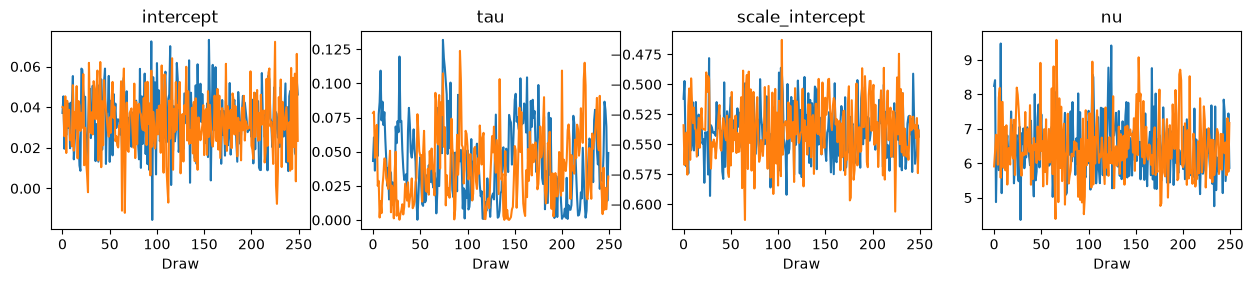

Smoke runtime seconds: 157.8


,player_id,game_id,game_date,season_year,minutes,start_position,b_prior_appearances,b_min_lag_1,b_min_ewm_10,q05,...,q50,q60,q70,q80,q90,q95,nll,pit,p_gt_48,p_gt_60
0,1629629,0022200135,2022-11-05,2022-23,37.100000,G,8,15.166667,23.535194,8.469916,...,18.669174,20.145092,21.906554,23.923379,26.759454,29.702712,6.198082,0.990885,0.001051,0.000170
1,1626181,0022200170,2022-11-09,2022-23,24.366667,,11,27.566667,23.548271,14.951065,...,26.488831,27.863458,29.827186,32.340188,35.960282,39.527124,2.811851,0.386296,0.005208,0.000604
2,1630583,0022200169,2022-11-09,2022-23,22.983333,F,11,18.483333,32.384100,17.078376,...,25.606092,27.051006,28.487524,30.316417,32.481000,34.736190,2.684409,0.328905,0.001637,0.000173
3,203903,0022200131,2022-11-04,2022-23,29.300000,G,9,33.350000,30.278703,24.452997,...,32.558610,33.905974,35.004524,36.236543,38.466612,40.697810,2.774930,0.240456,0.006613,0.000379
4,1629670,0022200180,2022-11-11,2022-23,29.050000,G,11,17.283333,16.506922,7.275596,...,16.875769,18.394301,20.607134,22.930264,26.884896,29.757185,4.412182,0.947717,0.001070,0.000183


This smoke fit does not authorize full comparison or model export.


In [30]:
if RUN_SMOKE:
    smoke_candidates = train_pool.loc[train_pool.game_date < FOLD_EDGES[0]]
    smoke_train = smoke_candidates.sample(min(3000, len(smoke_candidates)), random_state=SEED).copy()
    smoke_test = train_pool.loc[train_pool.game_date.between(
        FOLD_EDGES[0], FOLD_EDGES[0] + pd.Timedelta(days=14), inclusive="left")]
    smoke_test = smoke_test.sample(min(500, len(smoke_test)), random_state=SEED).copy()
    if smoke_train.empty or smoke_test.empty:
        raise ValueError("Insufficient data for the smoke split")
    smoke_fit = fit_bayes(smoke_train, method="nuts", draws=250, tune=250, chains=2)
    diagnostics(smoke_fit)
    smoke_predictions = predict_bayes(smoke_fit, smoke_test, n_draws=512)
    print("Smoke runtime seconds:", round(smoke_fit["fit_seconds"], 1))
    display(smoke_predictions.head())
    print("This smoke fit does not authorize full comparison or model export.")


## 6. Comparable scores and paired uncertainty

All baseline comparisons below use rows where **both** last-game and EWMA exist. Also score Bayesian/XGBoost on all appearances, so excluding cold starts does not conceal a problem. Display all 11 pinball scores, mean pinball, q50 pinball/MAE, interval coverage/width, median balance, and large-error rate.

The day-cluster paired bootstrap measures loss differences on the same rows and resamples calendar dates to retain same-night correlation. It does not fully handle serial dependence; corroborate a promising result with contiguous-week blocks and stability across folds. Interval exclusion of zero is not a substitute for a useful effect size.

Bayesian minutes negative log density is a **continuous density score**, not the discrete stat-PMF log score. The tree knots do not define a unique full density, so no tree density comparison is invented here.


In [38]:
def pinball(y, prediction, q):
    residual = np.asarray(y) - np.asarray(prediction)
    return np.maximum(q * residual, (q - 1) * residual)


def score_predictions(prediction):
    if prediction.empty:
        raise ValueError("Cannot score an empty slice")
    required = ["minutes"] + [f"q{round(q * 100):02d}" for q in QUANTILES]
    if not np.isfinite(prediction[required].to_numpy(dtype=float)).all():
        raise ValueError("Cannot score nonfinite outcomes/quantiles")
    y = prediction.minutes.to_numpy()
    q50 = prediction.q50.to_numpy()
    result = {"rows": len(prediction), "q50_pinball": pinball(y, q50, .5).mean(),
        "mae": np.abs(y - q50).mean(), "median_ae": np.median(np.abs(y - q50)),
        "miss_ge_10": np.mean(np.abs(y - q50) >= 10), "fraction_below_q50": np.mean(y < q50)}
    for low, high, label in [("q10", "q90", "80"), ("q05", "q95", "90")]:
        result[f"coverage_{label}"] = np.mean((y >= prediction[low]) & (y <= prediction[high]))
        result[f"width_{label}"] = np.mean(prediction[high] - prediction[low])
    for knot in QUANTILES:
        result[f"pinball_q{round(knot * 100):02d}"] = pinball(y, prediction[f"q{round(knot * 100):02d}"], knot).mean()
    result["mean_pinball"] = np.mean([result[f"pinball_q{round(k * 100):02d}"] for k in QUANTILES])
    if "nll" in prediction:
        result["minutes_nll"] = prediction.nll.mean()
    return result


def paired_day_bootstrap(dates, losses_a, losses_b, repetitions=2000):
    d = pd.DataFrame({"date": np.asarray(dates), "delta": np.asarray(losses_a) - np.asarray(losses_b)})
    if d.empty or not np.isfinite(d.delta.to_numpy()).all():
        raise ValueError("Paired comparison needs finite nonempty losses")
    aggregate = d.groupby("date").delta.agg(["sum", "size"]).to_numpy()
    rng = np.random.default_rng(SEED)
    values = np.empty(repetitions)
    for i in range(repetitions):
        selected = aggregate[rng.integers(0, len(aggregate), size=len(aggregate))]
        values[i] = selected[:, 0].sum() / selected[:, 1].sum()
    return {"delta_a_minus_b": d.delta.mean(), "low95": np.quantile(values, .025),
            "high95": np.quantile(values, .975)}


def matched_xgb(train, test, prep):
    model = XGBRegressor(objective="reg:quantileerror", quantile_alpha=QUANTILES,
        random_state=SEED, **XGB_PARAMS)
    start = time.perf_counter()
    model.fit(transform(train, prep)["x"], train.minutes)
    fit_seconds = time.perf_counter() - start
    predicted = model.predict(transform(test, prep)["x"])
    crossing = np.mean(np.any(np.diff(predicted, axis=1) < 0, axis=1))
    predicted = np.sort(predicted, axis=1)
    output = test[["player_id", "game_id", "game_date", "season_year", "minutes", "start_position",
                   "b_prior_appearances", "b_min_lag_1", "b_min_ewm_10"]].copy().reset_index(drop=True)
    for j, knot in enumerate(QUANTILES):
        output[f"q{round(knot * 100):02d}"] = predicted[:, j]
    return output, {"fit_seconds": fit_seconds, "crossing_before_sort": crossing}


def run_fold(train, test, name):
    if train.empty or test.empty or train.game_date.max() >= test.game_date.min():
        raise ValueError("Empty fold or training overlaps evaluation")
    fit = fit_bayes(train)
    diagnostics(fit)
    require_fit_quality(fit)
    bayes = predict_bayes(fit, test)
    bayes["fold"] = name
    scores = [{"fold": name, "model": "bayes_all", **score_predictions(bayes),
               "fit_seconds": fit["fit_seconds"], "predict_seconds": bayes.attrs["predict_seconds"]}]
    common = test[["b_min_lag_1", "b_min_ewm_10"]].notna().all(axis=1).to_numpy()
    paired_bayes = bayes.loc[common]
    scores.append({"fold": name, "model": "bayes_common", **score_predictions(paired_bayes)})
    comparisons = []
    for column in ["b_min_lag_1", "b_min_ewm_10"]:
        base_loss = pinball(paired_bayes.minutes, paired_bayes[column], .5)
        scores.append({"fold": name, "model": column, "rows": len(paired_bayes),
                       "q50_pinball": base_loss.mean(), "mae": 2 * base_loss.mean()})
        comparisons.append({"fold": name, "comparison": f"bayes minus {column}",
            **paired_day_bootstrap(paired_bayes.game_date,
                pinball(paired_bayes.minutes, paired_bayes.q50, .5), base_loss)})
    tree = None
    if RUN_MATCHED_XGB:
        tree, tree_info = matched_xgb(train, test, fit["prep"])
        tree["fold"] = name
        scores.append({"fold": name, "model": "xgb_all", **score_predictions(tree), **tree_info})
        scores.append({"fold": name, "model": "xgb_common", **score_predictions(tree.loc[common])})
        comparisons.append({"fold": name, "comparison": "bayes minus matched xgb (all rows)",
            **paired_day_bootstrap(bayes.game_date, pinball(bayes.minutes, bayes.q50, .5),
                                  pinball(tree.minutes, tree.q50, .5))})
    return fit, bayes, tree, scores, comparisons


## 7. Walk-forward: make decisions here

Fold intervals are **[start, end)**. These boundaries approximate the printed fold labels supplied in the conversation; confirm exact row membership against the original notebook before claiming a reproduction of its scores. Report equal-fold means and row-weighted pooled scores separately. Each fold is trained on all available train-pool appearances before its start, with fixed experiment choices.

Do not pick a winner from a short smoke fit. Full NUTS on the complete history may be expensive; measure it first. If inference fails, simplify correlated location terms or the hierarchy using training-period evidence before expanding the model.


In [ ]:
fold_predictions, tree_predictions, score_rows, comparison_rows = [], [], [], []
if RUN_WALK_FORWARD:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for fold, (start, end) in enumerate(zip(FOLD_EDGES[:-1], FOLD_EDGES[1:]), 1):
        train = train_pool.loc[train_pool.game_date < start].copy()
        test = train_pool.loc[train_pool.game_date.between(start, end, inclusive="left")].copy()
        print(f"Fold {fold}: {len(train):,} train, {len(test):,} test; {start.date()} to {end.date()} exclusive")
        fit, bayes, tree, scores, comparisons = run_fold(train, test, str(fold))
        fold_predictions.append(bayes)
        if tree is not None:
            tree_predictions.append(tree)
        score_rows.extend(scores)
        comparison_rows.extend(comparisons)
        bayes.to_parquet(OUTPUT_DIR / f"fold_{fold}_bayes.parquet", index=False)
        if tree is not None:
            tree.to_parquet(OUTPUT_DIR / f"fold_{fold}_xgb.parquet", index=False)
        pd.DataFrame(score_rows).to_csv(OUTPUT_DIR / "walk_forward_scores.csv", index=False)
        pd.DataFrame(comparison_rows).to_csv(OUTPUT_DIR / "paired_comparisons.csv", index=False)
    display(pd.DataFrame(score_rows))
    display(pd.DataFrame(comparison_rows))
    numeric = ["q50_pinball", "mean_pinball", "coverage_80", "coverage_90", "width_80"]
    display(pd.DataFrame(score_rows).groupby("model")[numeric].agg(["mean", "std"]))
    pooled = pd.concat(fold_predictions, ignore_index=True)
    display(pd.Series(score_predictions(pooled), name="row_weighted_bayes"))
else:
    print("Walk-forward disabled. Enable only after the smoke fit and prior checks.")


## 8. Calibration, weak slices, and tail behavior

Starter/bench slices below use realized starting **only for evaluation labels**. Low-minute bands use Bayesian predicted q50; compare both models on these same rows. Also inspect sparse histories and season openers. Coverage near nominal with much wider intervals is not an automatic improvement.

The PIT should be approximately uniform for calibrated continuous predictions. Minutes are recorded with finite precision, so interpret small spikes cautiously. Quantile calibration plots and interval widths should be inspected by fold as well as pooled.


In [35]:
def inspect_predictions(prediction, tree=None):
    y = prediction.minutes.to_numpy()
    empirical = [np.mean(y <= prediction[f"q{round(q * 100):02d}"]) for q in QUANTILES]
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    axes[0].plot(QUANTILES, empirical, marker="o", label="Bayesian")
    if tree is not None:
        axes[0].plot(QUANTILES, [np.mean(y <= tree[f"q{round(q * 100):02d}"]) for q in QUANTILES],
                     marker="x", label="Matched XGBoost")
    axes[0].plot([0, 1], [0, 1], linestyle="--")
    axes[0].set(xlabel="Nominal quantile", ylabel="Fraction at/below forecast")
    axes[0].legend()
    axes[1].hist(prediction.pit, bins=np.linspace(0, 1, 11), density=True)
    axes[1].axhline(1, linestyle="--")
    axes[1].set(xlabel="Posterior predictive PIT", ylabel="Density")
    axes[2].scatter(prediction.q50, prediction.q90 - prediction.q10, s=2, alpha=.15)
    axes[2].set(xlabel="Predicted q50 minutes", ylabel="80% interval width")
    plt.tight_layout(); plt.show()
    starter = prediction.start_position.isin(["G", "F", "C"])
    slices = {"starters": starter, "bench": ~starter,
              "q50_under_15": prediction.q50 < 15,
              "q50_15_to_24": prediction.q50.between(15, 24, inclusive="left"),
              "q50_24_to_31": prediction.q50.between(24, 31, inclusive="left"),
              "q50_31_plus": prediction.q50 >= 31,
              "prior_appearances_under_5": prediction.b_prior_appearances < 5,
              "season_openers": prediction.b_prior_appearances == 0}
    rows = []
    for label, mask in slices.items():
        if mask.any():
            rows.append({"slice": label, "model": "bayes", **score_predictions(prediction.loc[mask])})
            if tree is not None:
                rows.append({"slice": label, "model": "matched_xgb", **score_predictions(tree.loc[mask])})
    display(pd.DataFrame(rows))
    print("Predicted/observed mass >48:", prediction.p_gt_48.mean(), np.mean(y > 48))
    print("Predicted/observed mass >60:", prediction.p_gt_60.mean(), np.mean(y > 60))
    display(prediction.assign(abs_error=np.abs(y - prediction.q50)).nlargest(20, "abs_error")
            [["player_id", "game_date", "minutes", "q05", "q50", "q95", "abs_error"]])

if fold_predictions:
    pooled = pd.concat(fold_predictions, ignore_index=True)
    pooled_tree = pd.concat(tree_predictions, ignore_index=True) if tree_predictions else None
    inspect_predictions(pooled, pooled_tree)
    for b in fold_predictions:
        inspect_predictions(b)


## 9. Previously scored holdout: enable after freezing choices

2025–26 is not an untouched dataset anymore: the original model has already been scored there. Keep this notebook's feature/prior/inference decisions independent of its outcomes. Record a freeze file before scoring, and use a future period for any decisions subsequently informed by this comparison.

The model is fitted once on the full 2019–2025 train pool. Holdout histories may use earlier **completed** holdout games, exactly as a fixed model would live; parameters and preprocessing remain frozen.


In [36]:
final_fit = None
if RUN_FINAL_TRAIN_FIT and not RUN_HOLDOUT:
    final_fit = fit_bayes(train_pool)
    diagnostics(final_fit)
    require_fit_quality(final_fit)

if RUN_HOLDOUT:
    if not CONFIG_FROZEN:
        raise RuntimeError("Freeze training-period choices and set CONFIG_FROZEN=True before holdout scoring")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    freeze = {"created_utc": pd.Timestamp.now(tz="UTC").isoformat(), "versions": versions,
              "method": METHOD, "draws": DRAWS, "tune": TUNE, "chains": CHAINS,
              "seed": SEED, "features": LOCATION_FEATURES, "scale_features": SCALE_FEATURES,
              "quantiles": QUANTILES.tolist(), "xgb_params": XGB_PARAMS, "train_end_exclusive": str(TRAIN_END.date()),
              "label_min_sec_unit": MIN_SEC_UNIT,
              "note": "Initial priors and likelihood are defined in the accompanying notebook."}
    (OUTPUT_DIR / "freeze.json").write_text(json.dumps(freeze, indent=2))
    final_fit, holdout_bayes, holdout_tree, holdout_scores, holdout_comparisons = run_fold(train_pool, holdout, "2025-26")
    display(pd.DataFrame(holdout_scores))
    display(pd.DataFrame(holdout_comparisons))
    inspect_predictions(holdout_bayes, holdout_tree)
    holdout_bayes.to_parquet(OUTPUT_DIR / "holdout_bayes.parquet", index=False)
    if holdout_tree is not None:
        holdout_tree.to_parquet(OUTPUT_DIR / "holdout_xgb.parquet", index=False)
else:
    print("Holdout scoring is disabled.")


Holdout scoring is disabled.


## 10. Export and simulation integration

Export the frozen posterior, training-only preprocessing, and version metadata. The exported sampler does not need to refit the model. Record the feature-builder code/notebook with the artifact; these arrays alone do not reconstruct live features.

For a small set of priced players, obtain minutes by `inverse_minutes_cdf` and independently draw the rate uniform. Numerical mixture inversion is deliberately explicit and may be slow; benchmark it before production. Direct posterior predictive samples are faster if your simulator accepts samples instead of an inverse-CDF interface.

Keep the existing rate model, conditional count distribution/PMF, market timestamps, and settlement rules fixed when comparing Bayesian minutes against XGBoost minutes. Only the minutes component changes. Do not add a new Poisson layer if your existing PMF already includes outcome noise.

Enable `RUN_FINAL_TRAIN_FIT` to fit/export on the train pool without enabling holdout scoring. Keep exported training-only experiments distinct from a frozen production model.


In [ ]:
def export_fit(fit, directory):
    require_fit_quality(fit)
    directory.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(directory / "posterior.npz", **posterior_arrays(fit))
    (directory / "preprocessing.json").write_text(json.dumps(fit["prep"], indent=2))
    (directory / "metadata.json").write_text(json.dumps({
        "method": fit["method"], "versions": versions, "seed": SEED,
        "target": "minutes conditional on appearance", "scale_factor": 10,
        "likelihood": "StudentT positive-truncated log likelihood via Potential", "quantiles": QUANTILES.tolist(),
        "features": LOCATION_FEATURES, "scale_features": SCALE_FEATURES,
        "min_sec_unit": MIN_SEC_UNIT, "fit_seconds": fit["fit_seconds"], "train_rows": fit["train_rows"],
        "train_start": fit["train_start"], "train_end": fit["train_end"],
    }, indent=2))

    if fit["method"] == "nuts":
        az.summary(fit["idata"], var_names=["intercept", "beta", "tau", "player_effect",
                                          "scale_intercept", "gamma", "nu"]).to_csv(directory / "diagnostics.csv")
        np.savez_compressed(directory / "sampler_stats.npz",
            divergences=np.asarray(fit["idata"].sample_stats.diverging.values),
            bfmi=chain_bfmi(fit["idata"]))


def load_export(directory):
    with np.load(directory / "posterior.npz", allow_pickle=False) as archive:
        posterior = {name: archive[name] for name in archive.files}
    return {"posterior": posterior, "prep": json.loads((directory / "preprocessing.json").read_text())}

if final_fit is not None:
    export_fit(final_fit, OUTPUT_DIR / "frozen_model")

# Integration with YOUR existing rate sampler / conditional PMF:
# target_rows = build_features(history_plus_missing_target_rows).query("_target")
# minutes_u = rng.uniform(eps, 1-eps, size=(n_simulations, len(target_rows)))
# rate_u = rng.uniform(eps, 1-eps, size=(n_simulations, len(target_rows)))
# minutes_draws = inverse_minutes_cdf(frozen_fit, target_rows, minutes_u)
# rate_draws = your_existing_rate_inverse_cdf(target_rows, rate_u)
# pmf = your_existing_conditional_pmf(minutes_draws, rate_draws)
# p_over = pmf[..., outcomes > line].sum(axis=-1)
# p_push = pmf[..., outcomes == line].sum(axis=-1)


## 11. Checklist: is Bayesian minutes worth pursuing over XGBoost?

### Validity gates

- [ ] `ROOT` and `PROJECT_ROOT` point to the same NBA project; no duplicate loaders/evaluation blocks remain.
- [ ] Prior/predictive arrays are entirely finite; NaN comparisons are never interpreted as probabilities.
- [ ] `label_audit.csv` explains any sample-membership discrepancy against the original notebook.
- [ ] Minutes units, duplicate keys, season resets, and rolling-window meanings are verified.
- [ ] Tonight's realized starts/participation never enter predictors. Historical market inputs meet the intended timestamp, or are removed from both challengers.
- [ ] Preprocessing and player vocabulary are fitted before each fold. A synthetic live row does not update history.
- [ ] NUTS has acceptable diagnostics; ADVI results are corroborated against NUTS. Predictive results are stable when posterior/predictive draw counts increase.
- [ ] Prior/posterior tails are plausible. Check >48 and >60 minute mass; a heavy-tailed likelihood can fail here.

### Prediction evidence

- [ ] Beat the better of last-game/EWMA on common rows across folds; print those actual scores.
- [ ] Compare q50 pinball against matched-input XGBoost on identical rows. Examine paired day-cluster intervals, fold stability, and contiguous-week sensitivity, rather than one fold or one p-value.
- [ ] Preserve accuracy on all rows, including cold starts and new players. Inspect player identity pooling rather than assuming it helps.
- [ ] Improve or preserve mean pinball across all 11 knots. q50 alone is insufficient for a simulation distribution.
- [ ] Get useful 80%/90% coverage without buying it solely through wider bands. Inspect bench and under-15-minute slices first.
- [ ] Check PIT/quantile calibration by fold, season, history size, and starter/bench evaluation labels.
- [ ] Review 10+ minute misses and continuous minutes log density. Do not compare this log density directly with discrete PMF log score.

### Simulation and price evidence

- [ ] Replace only minutes in the current independent-uniform simulator and preserve the conditional stat PMF.
- [ ] Evaluate over/under Brier and log loss at actual quoted lines, not only fixed diagnostic thresholds.
- [ ] Compare discrete stat-PMF log score separately from line-event scores.
- [ ] Inspect per-line probability differences, large changes, and whether decisions change at quoted odds. A small average Brier gain does not measure price movement.
- [ ] Use predeclared edge rules, timestamped quotes, bookmaker-margin adjustment, and actual push/DNP settlement treatment. Quotes are evaluation inputs supplied separately, not invented silver features.
- [ ] Treat any prospective bankroll/ROI evidence with game/week-cluster uncertainty and enough observations; do not select a rule on the same trial.

### Cost and decision

- [ ] Measure fit time, prediction latency, memory, export size, and refresh frequency.
- [ ] A practically useful improvement is specified **before** the next evaluation. Record acceptable price-error/latency tradeoffs rather than inventing a threshold from favorable results.

**Pursue:** diagnostics pass and training-period folds show a repeatable accuracy/calibration advantage or materially better stat probabilities at tolerable cost.

**Keep as a challenger:** median performance is similar but uncertainty may help; test that in the frozen simulator.

**Stop or simplify:** inference is unstable, tails are implausible, or matched XGBoost is consistently better and the PMF/line tests show no practical gain.

Reference only: original XGBoost walk-forward q50 pinball 2.226 and 80% coverage 79.1%; previously scored holdout q50 pinball 2.223, 80% coverage 79.6%, and 90% coverage 89.7%. These are not measured outputs of this notebook and use different feature semantics.
